# Analiza wstępna — znaki drogowe


In [1]:
import os
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

DATA_PATH = "dane-wkeska"
IMG_PATH = "img"
SIZE = 64 # rozmiar do ktorego skalujemy wycinki przy liczeniu histogramow
os.makedirs(IMG_PATH, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

## Wczytanie opisu danych

`labels.csv` ma jeden wiersz na wycinek: plik, kod znaku, zdjęcie źródłowe, współrzędne wycinka i pogodę. Grupa znaku to pierwsza litera kodu.

In [2]:
labels = pd.read_csv(os.path.join(DATA_PATH, "labels.csv"))
labels["grupa"] = labels["kod"].str[0]

GROUP_NAMES = {"A": "ostrzegawcze (A)", "B": "zakazu (B)", "C": "nakazu (C)", "D": "informacyjne (D)"}
GROUP_COLORS = {"A": "#e0a800", "B": "#c62828", "C": "#1e88e5", "D": "#3949ab"}
GROUPS = ["A", "B", "D"] # grupy uzyte w projekcie, C ma za malo zdjec
SIGNS = {"D-6": "#1565c0", "D-18": "#00897b", "B-33": "#c62828"} # znaki uzyte w projekcie

print(f"Wycinków: {len(labels)}, zdjęć źródłowych: {labels['zrodlo'].nunique()}, typów znaków: {labels['kod'].nunique()}")
labels.groupby("grupa").size()

Wycinków: 149, zdjęć źródłowych: 97, typów znaków: 25


grupa
A    30
B    49
C     7
D    63
dtype: int64

In [3]:
def load_img(path, size=SIZE):
    img = cv2.imread(os.path.join(DATA_PATH, path))
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA) # inter_area usrednia pixele przy zmniejszaniu

def show(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def pixels(df):
    # wszystkie piksele z wycinkow jako tablica (N, 3) w BGR
    return np.concatenate([load_img(p).reshape(-1, 3) for p in df["plik"]])

def to_space(px, code):
    return cv2.cvtColor(px[None], code)[0]

def hist(ax, values, color, label=None, bins=64, range=None):
    ax.hist(values, bins, range=range, density=True, histtype="step", lw=1.6, color=color, label=label)

## 1. Zdjęcia

### Rozkład klas

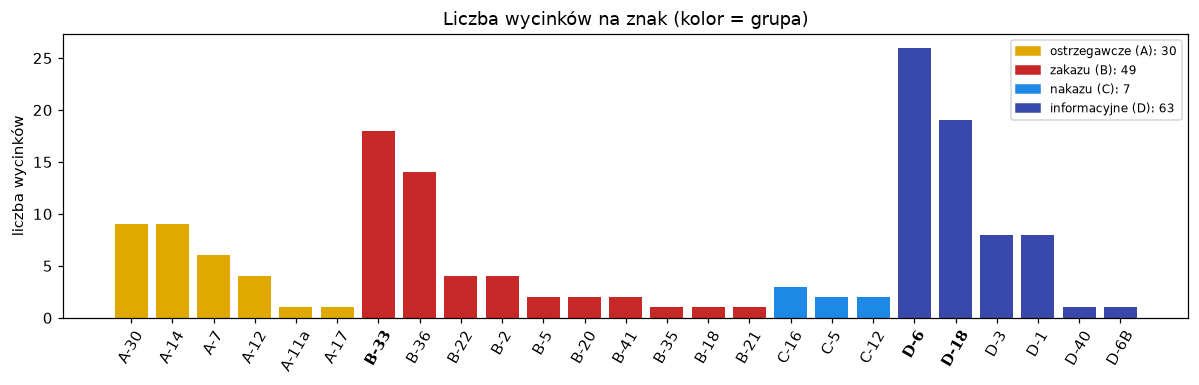

In [4]:
counts = Counter(labels["kod"])
codes = sorted(counts, key=lambda k: (k[0], -counts[k]))

plt.figure(figsize=(11, 3.6))
plt.bar(codes, [counts[k] for k in codes], color=[GROUP_COLORS[k[0]] for k in codes])
for k in SIGNS:
    plt.gca().get_xticklabels()[codes.index(k)].set_fontweight("bold")
plt.xticks(rotation=60)
plt.ylabel("liczba wycinków")
plt.title("Liczba wycinków na znak (kolor = grupa)")
plt.legend(handles=[Patch(color=GROUP_COLORS[g], label=f"{GROUP_NAMES[g]}: {(labels['grupa'] == g).sum()}") for g in "ABCD"], fontsize=8)
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/rozklad.png")
plt.show()

### Przykłady

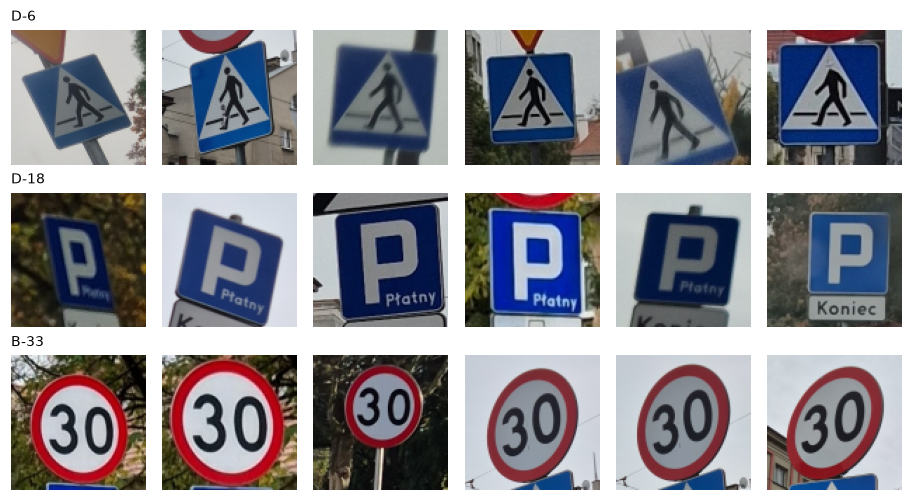

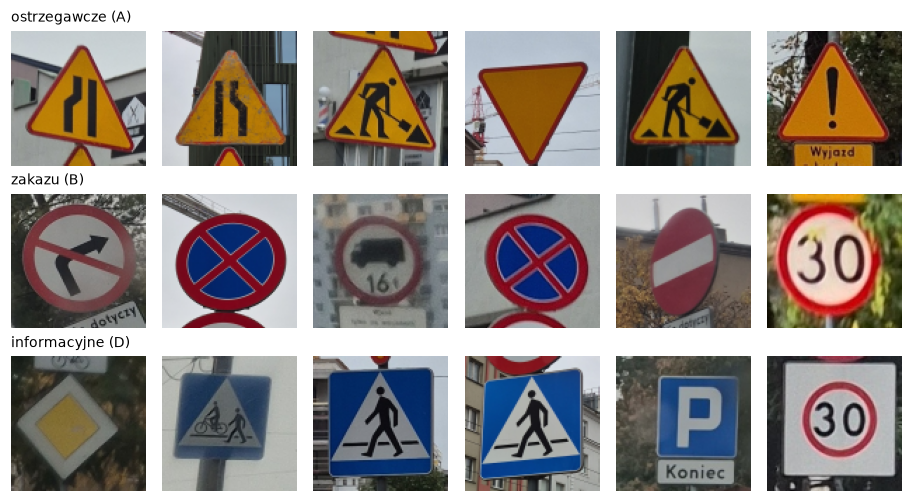

In [5]:
rng = np.random.default_rng(3)

def examples_grid(rows, filename, n=6):
    fig, axes = plt.subplots(len(rows), n, figsize=(n * 1.4, len(rows) * 1.55))
    for ax_row, (title, df) in zip(axes, rows):
        chosen = rng.choice(len(df), min(n, len(df)), replace=False)
        for j, ax in enumerate(ax_row):
            ax.axis("off")
            if j < len(chosen):
                ax.imshow(show(load_img(df["plik"].iloc[chosen[j]], 96)))
        ax_row[0].set_title(title, loc="left", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{IMG_PATH}/{filename}")
    plt.show()

examples_grid([(k, labels[labels["kod"] == k]) for k in SIGNS], "przyklady_znaki.png")
examples_grid([(GROUP_NAMES[g], labels[labels["grupa"] == g]) for g in GROUPS], "przyklady_grupy.png")

### Warunki

Ręcznie wybrane wycinki pokazujące różne warunki zdjęć.

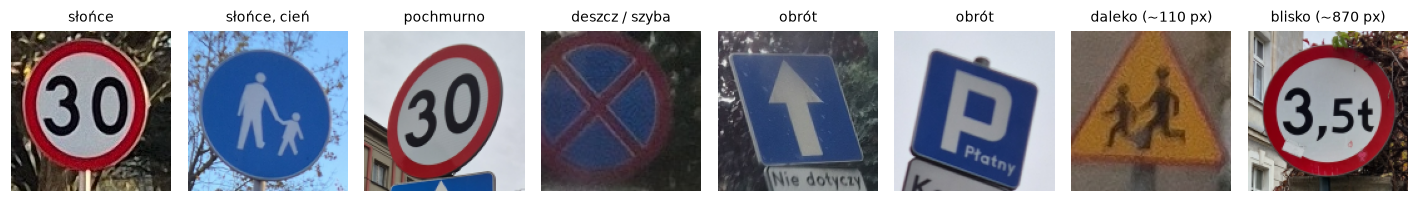

pogoda
pochmurno    141
slonce         8
Name: count, dtype: int64


In [6]:
conditions = [
    ("słońce", "B33/5.jpg"),
    ("słońce, cień", "C16/2.jpg"),
    ("pochmurno", "B33/7.jpg"),
    ("deszcz / szyba", "B36/0.jpg"),
    ("obrót", "D3/0.jpg"),
    ("obrót", "D18/4.jpg"),
    ("daleko (~110 px)", "A17/0.jpg"),
    ("blisko (~870 px)", "B18/0.jpg"),
]
fig, axes = plt.subplots(1, len(conditions), figsize=(13, 2.1))
for ax, (title, path) in zip(axes, conditions):
    ax.imshow(show(load_img(path, 128)))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/warunki.png")
plt.show()

print(labels["pogoda"].value_counts())

## 2. Wstępna analiza

Histogramy liczone na wycinkach przeskalowanych do 64×64, znormalizowane (`density=True`), żeby dało się porównać grupy o różnej liczności.

### Jasność i RGB

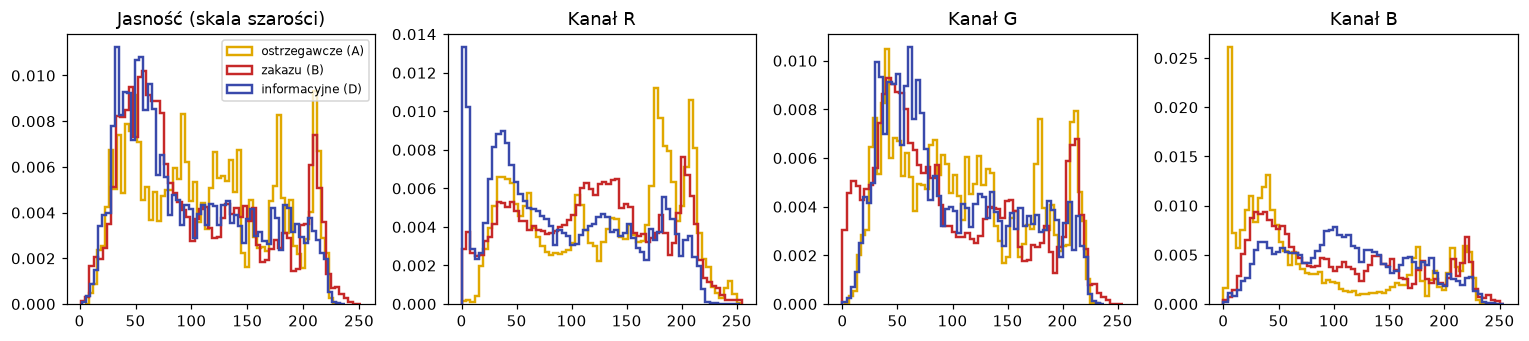

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for g in GROUPS:
    px = pixels(labels[labels["grupa"] == g])
    gray = to_space(px, cv2.COLOR_BGR2GRAY).ravel()
    hist(axes[0], gray, GROUP_COLORS[g], GROUP_NAMES[g])
    for ax, ch in zip(axes[1:], [2, 1, 0]): # opencv trzyma kanaly jako BGR
        hist(ax, px[:, ch], GROUP_COLORS[g])
axes[0].set_title("Jasność (skala szarości)")
for ax, name in zip(axes[1:], "RGB"):
    ax.set_title(f"Kanał {name}")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/hist_jasnosc_rgb.png")
plt.show()

### HSV i Lab — grupy

Histogram barwy H liczymy tylko dla pikseli nasyconych (S > 90, V > 50). Szare niebo i białe tło mają przypadkową barwę i zasłoniłyby piki.

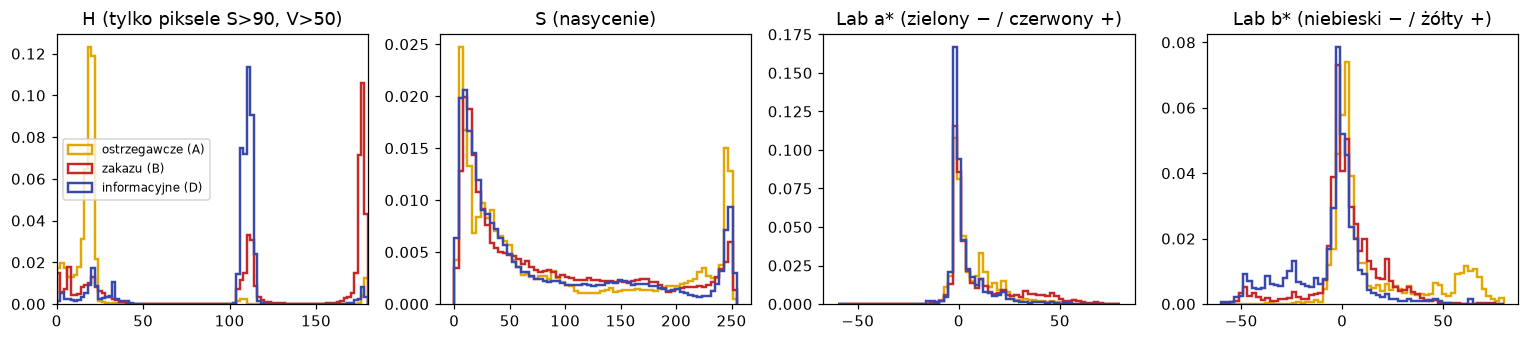

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for g in GROUPS:
    px = pixels(labels[labels["grupa"] == g])
    hsv = to_space(px, cv2.COLOR_BGR2HSV)
    lab = to_space(px, cv2.COLOR_BGR2LAB).astype(int)
    saturated = (hsv[:, 1] > 90) & (hsv[:, 2] > 50)
    hist(axes[0], hsv[saturated, 0], GROUP_COLORS[g], GROUP_NAMES[g], bins=90, range=(0, 180))
    hist(axes[1], hsv[:, 1], GROUP_COLORS[g])
    hist(axes[2], lab[:, 1] - 128, GROUP_COLORS[g], range=(-60, 80)) # opencv przesuwa a* i b* o 128
    hist(axes[3], lab[:, 2] - 128, GROUP_COLORS[g], range=(-60, 80))
axes[0].set_title("H (tylko piksele S>90, V>50)")
axes[0].set_xlim(0, 180)
axes[1].set_title("S (nasycenie)")
axes[2].set_title("Lab a* (zielony − / czerwony +)")
axes[3].set_title("Lab b* (niebieski − / żółty +)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/hist_hsv_lab_grupy.png")
plt.show()

### Maski kolorów

Te same progi HSV co w potoku: czerwień „zawija się” w HSV, więc bierzemy oba końce skali H.

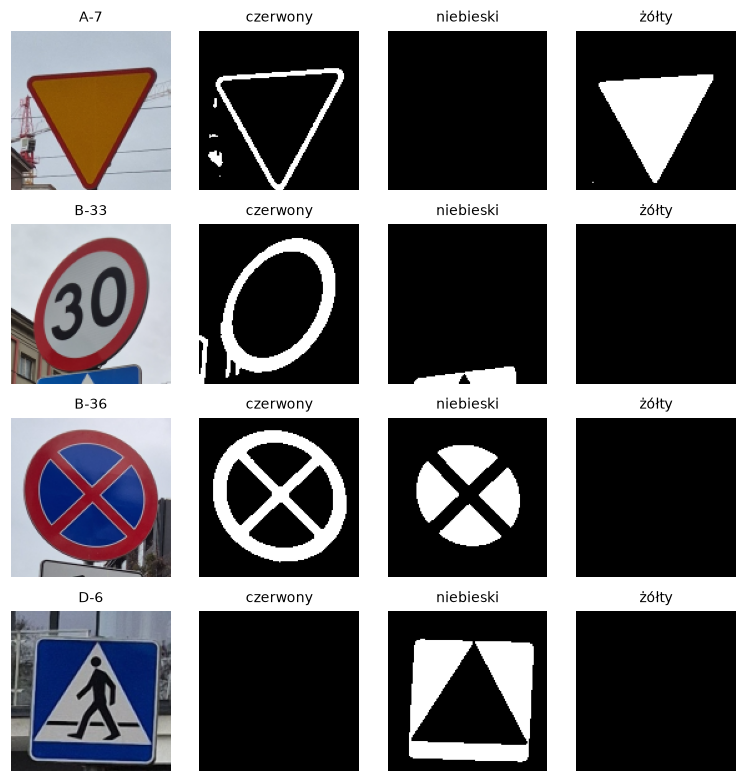

In [9]:
def color_masks(img):
    blur = cv2.GaussianBlur(img, (3, 3), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    red = cv2.inRange(hsv, (0, 70, 50), (10, 255, 255)) | cv2.inRange(hsv, (170, 70, 50), (180, 255, 255))
    blue = cv2.inRange(hsv, (100, 100, 40), (130, 255, 255))
    yellow = cv2.inRange(hsv, (15, 80, 80), (35, 255, 255))
    return red, blue, yellow

mask_examples = ["A7/5.jpg", "B33/7.jpg", "B36/5.jpg", "D6/16.jpg"]
fig, axes = plt.subplots(len(mask_examples), 4, figsize=(7, len(mask_examples) * 1.8))
for ax_row, path in zip(axes, mask_examples):
    img = load_img(path, 128)
    ax_row[0].imshow(show(img))
    ax_row[0].set_title(labels.set_index("plik").loc[path, "kod"], fontsize=9)
    for ax, mask, title in zip(ax_row[1:], color_masks(img), ["czerwony", "niebieski", "żółty"]):
        ax.imshow(mask, cmap="gray")
        ax.set_title(title, fontsize=9)
    for ax in ax_row:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/maski.png")
plt.show()

Średni udział pikseli w każdej masce (tabela w README):

In [10]:
def mask_shares(df):
    shares = np.array([[m.mean() / 255 * 100 for m in color_masks(load_img(p))] for p in df["plik"]])
    return shares.mean(axis=0)

rows = [(GROUP_NAMES[g], labels[labels["grupa"] == g]) for g in "ABCD"] + [(k, labels[labels["kod"] == k]) for k in SIGNS]
pd.DataFrame(
    [[len(df), *mask_shares(df)] for _, df in rows],
    index=[name for name, _ in rows],
    columns=["n", "czerwony %", "niebieski %", "żółty %"],
).round(1)

,n,czerwony %,niebieski %,żółty %
ostrzegawcze (A),30,9.7,0.4,25.4
zakazu (B),49,22.4,7.5,3.6
nakazu (C),7,0.2,33.2,1.9
informacyjne (D),63,2.2,24.3,3.5
D-6,26,3.0,24.1,2.1
D-18,19,0.8,31.1,2.7
B-33,18,20.3,1.6,4.6


### HSV — wybrane znaki

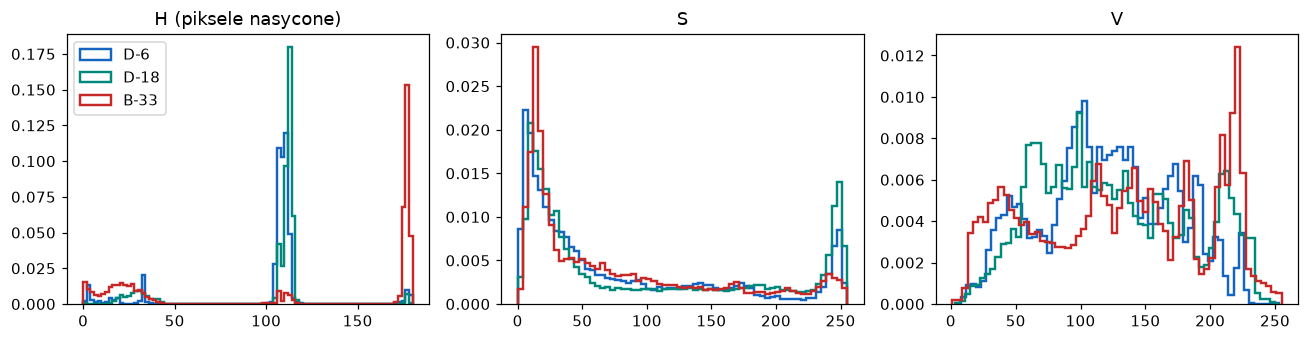

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for k, color in SIGNS.items():
    hsv = to_space(pixels(labels[labels["kod"] == k]), cv2.COLOR_BGR2HSV)
    saturated = (hsv[:, 1] > 90) & (hsv[:, 2] > 50)
    hist(axes[0], hsv[saturated, 0], color, k, bins=90, range=(0, 180))
    hist(axes[1], hsv[:, 1], color)
    hist(axes[2], hsv[:, 2], color)
axes[0].set_title("H (piksele nasycone)")
axes[1].set_title("S")
axes[2].set_title("V")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/hist_hsv_znaki.png")
plt.show()

### Wpływ warunków — słońce kontra pochmurno

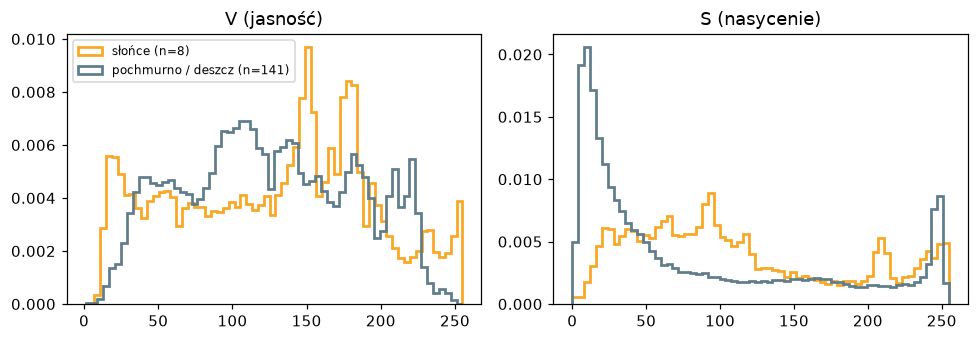

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for weather, color, name in [("slonce", "#f9a825", "słońce"), ("pochmurno", "#607d8b", "pochmurno / deszcz")]:
    df = labels[labels["pogoda"] == weather]
    hsv = to_space(pixels(df), cv2.COLOR_BGR2HSV)
    axes[0].hist(hsv[:, 2], 64, density=True, histtype="step", lw=1.8, color=color, label=f"{name} (n={len(df)})")
    axes[1].hist(hsv[:, 1], 64, density=True, histtype="step", lw=1.8, color=color)
axes[0].set_title("V (jasność)")
axes[1].set_title("S (nasycenie)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{IMG_PATH}/hist_warunki.png")
plt.show()